In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Imports and dataset path

In [4]:
import os
import pickle
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# EDIT THIS PATH to match the folder shown in the Colab Files panel.
# Google Drive example:
DATASET_PATH = "/content/drive/MyDrive/AI ML/cifar-100-python"

# If you uploaded/extracted the folder directly into the Colab runtime, it may be:
# DATASET_PATH = "/content/cifar-100-python"

for filename in ["train", "test", "meta"]:
    path = os.path.join(DATASET_PATH, filename)
    print(filename, "found:", os.path.isfile(path), "|", path)

# Stop early with a clear message if the path is incorrect.
if not all(os.path.isfile(os.path.join(DATASET_PATH, f)) for f in ["train", "test", "meta"]):
    raise FileNotFoundError(
        "CIFAR-100 files were not found. Check DATASET_PATH and ensure "
        "the folder contains train, test, and meta."
    )

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
train found: True | /content/drive/MyDrive/AI ML/cifar-100-python/train
test found: True | /content/drive/MyDrive/AI ML/cifar-100-python/test
meta found: True | /content/drive/MyDrive/AI ML/cifar-100-python/meta


**If the architecture diagram cell fails:** run `!pip install -q pydot` and `!apt-get -qq install graphviz`, then rerun the diagram cell.

## 2. Load the downloaded CIFAR-100 files

In [5]:
def load_cifar_pickle(file_path):
    with open(file_path, "rb") as file:
        return pickle.load(file, encoding="bytes")

train_dict = load_cifar_pickle(os.path.join(DATASET_PATH, "train"))
test_dict = load_cifar_pickle(os.path.join(DATASET_PATH, "test"))

# The CIFAR-100 Python files store image pixels in flattened channel-first form.
x_all = train_dict[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_all = np.array(train_dict[b"fine_labels"], dtype=np.int64)

x_test = test_dict[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_test = np.array(test_dict[b"fine_labels"], dtype=np.int64)

# Normalize image pixel values to [0, 1].
x_all = x_all.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

print("All training images:", x_all.shape)
print("Training labels:", y_all.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Number of classes:", len(np.unique(y_all)))

All training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)
Number of classes: 100


## 3. Create training and validation sets

In [6]:
x_train, x_val, y_train, y_val = train_test_split(
    x_all, y_all,
    test_size=0.1,
    random_state=SEED,
    stratify=y_all
)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Testing:", x_test.shape, y_test.shape)

Training: (45000, 32, 32, 3) (45000,)
Validation: (5000, 32, 32, 3) (5000,)
Testing: (10000, 32, 32, 3) (10000,)


## 4. Display sample images

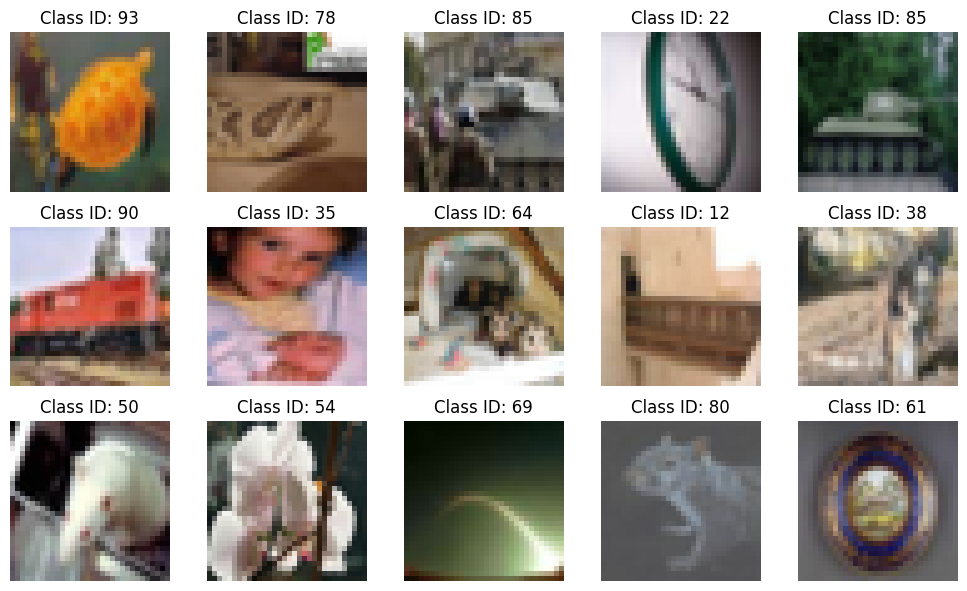

In [7]:
plt.figure(figsize=(10, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(f"Class ID: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Part 1 — Custom CNN


In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)
])

In [9]:
def build_custom_cnn():
    inputs = layers.Input(shape=(32, 32, 3))
    x = data_augmentation(inputs)
    x = layers.Conv2D(64, 3, padding="same", kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(64, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, 3, padding="same", kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(128, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Conv2D(256, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.35)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu", kernel_initializer="he_normal")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(100, activation="softmax")(x)
    return models.Model(inputs, outputs, name="Custom_CNN")

custom_cnn = build_custom_cnn()
custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
custom_cnn.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 649,380 (2.48 MB)

 Trainable params: 648,100 (2.47 MB)

 Non-trainable params: 1,280 (5.00 KB)

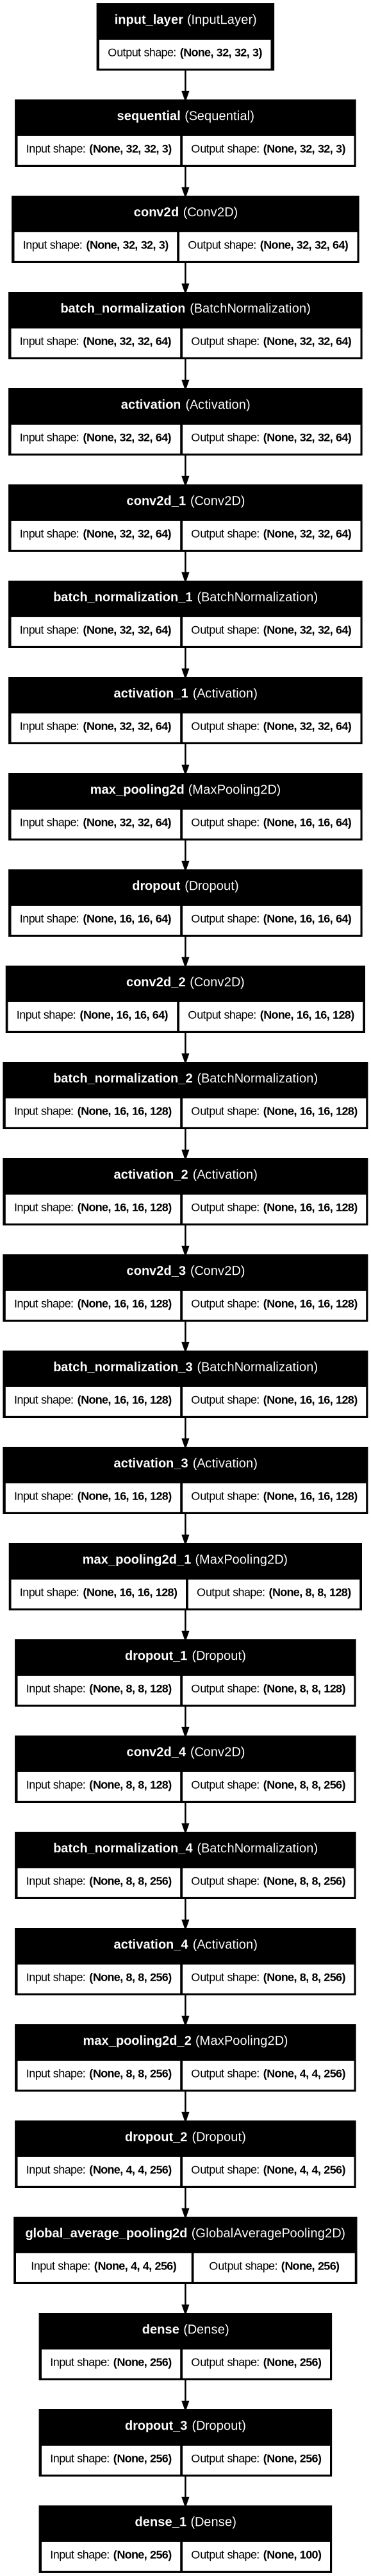

In [10]:
plot_model(custom_cnn, to_file="custom_cnn_architecture.png",
          show_shapes=True, show_layer_names=True, dpi=90)
display(Image("custom_cnn_architecture.png"))

### Train the Custom CNN

In [11]:
custom_callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=5, mode="max",
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint("best_custom_cnn.keras", monitor="val_accuracy",
                    mode="max", save_best_only=True, verbose=1)
]

history_custom = custom_cnn.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=custom_callbacks,
    verbose=1
)

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.0501 - loss: 4.4139
Epoch 1: val_accuracy improved from None to 0.10580, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 52ms/step - accuracy: 0.0740 - loss: 4.1324 - val_accuracy: 0.1058 - val_loss: 3.9021
Epoch 2/20
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.1247 - loss: 3.7357
Epoch 2: val_accuracy improved from 0.10580 to 0.15900, saving model to best_custom_cnn.keras

Epoch 2: finished saving model to best_custom_cnn.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.1357 - loss: 3.6577 - val_accuracy: 0.1590 - val_loss: 3.5344
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.1671 - loss: 3.4658
Epoch 3: val_accuracy improved from 0.15900 to 0.20020, saving model to best_custom_cnn.keras

Epoch 3: finished saving model to best_custom_cnn.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accura

## 6. Part 2 — VGG-16 adapted for CIFAR-100


In [12]:
def build_vgg16_cifar():
    inputs = layers.Input(shape=(32, 32, 3))
    x = data_augmentation(inputs)

    # Block 1: 2 convolutional layers, 64 filters
    for _ in range(2):
        x = layers.Conv2D(64, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal")(x)
    x = layers.MaxPooling2D(2)(x)

    # Block 2: 2 convolutional layers, 128 filters
    for _ in range(2):
        x = layers.Conv2D(128, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal")(x)
    x = layers.MaxPooling2D(2)(x)

    # Block 3: 3 convolutional layers, 256 filters
    for _ in range(3):
        x = layers.Conv2D(256, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal")(x)
    x = layers.MaxPooling2D(2)(x)

    # Block 4: 3 convolutional layers, 512 filters
    for _ in range(3):
        x = layers.Conv2D(512, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal")(x)
    x = layers.MaxPooling2D(2)(x)

    # Block 5: 3 convolutional layers, 512 filters; no extra pooling
    for _ in range(3):
        x = layers.Conv2D(512, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal")(x)


    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(100, activation="softmax")(x)
    return models.Model(inputs, outputs, name="VGG16_CIFAR100")

vgg16_model = build_vgg16_cifar()
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
vgg16_model.summary()

Model: "VGG16_CIFAR100"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │        51,300 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 15,028,644 (57.33 MB)

 Trainable params: 15,028,644 (57.33 MB)

 Non-trainable params: 0 (0.00 B)

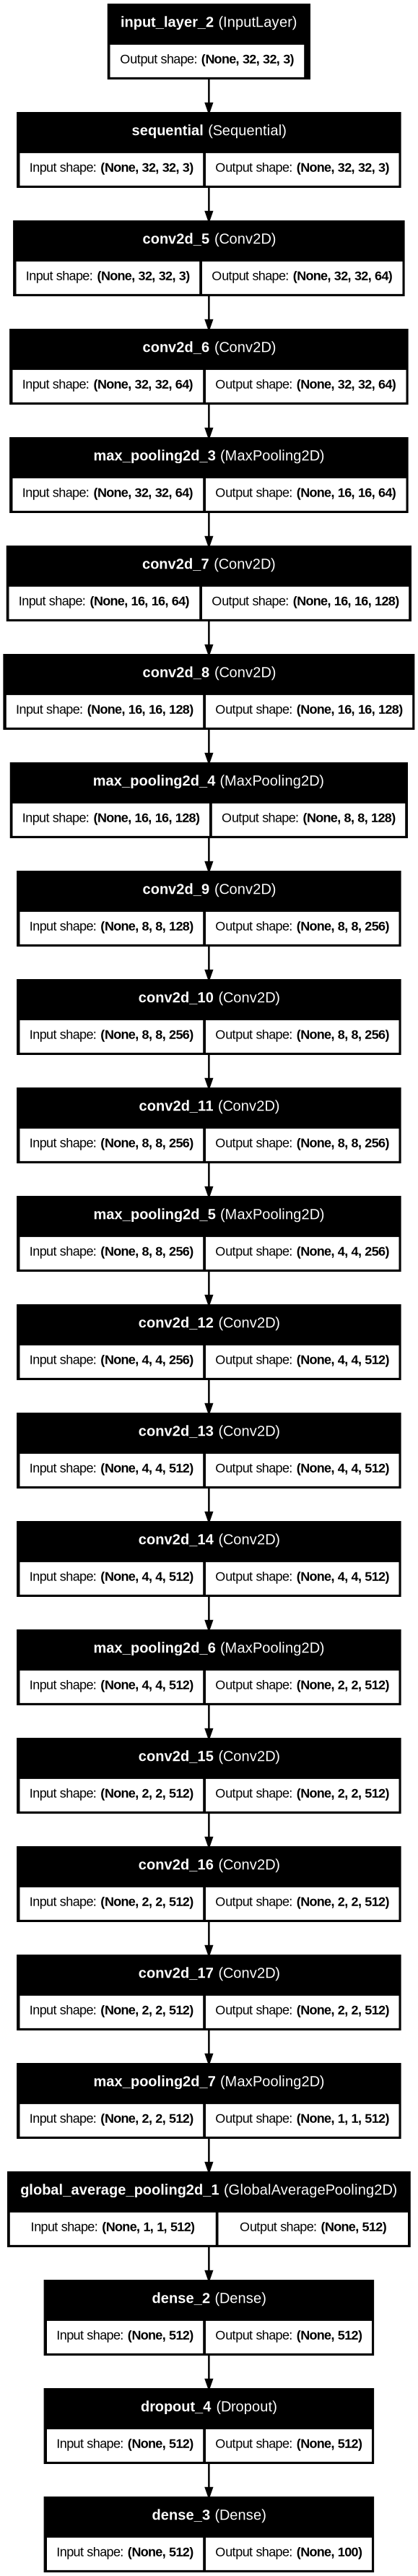

In [13]:
plot_model(vgg16_model, to_file="vgg16_architecture.png",
          show_shapes=True, show_layer_names=True, dpi=90)
display(Image("vgg16_architecture.png"))

### Train the VGG-16 model

In [14]:
vgg_callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=5, mode="max",
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint("best_vgg16_cifar.keras", monitor="val_accuracy",
                    mode="max", save_best_only=True, verbose=1)
]

history_vgg16 = vgg16_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=vgg_callbacks,
    verbose=1
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.0089 - loss: 4.6371
Epoch 1: val_accuracy improved from None to 0.01000, saving model to best_vgg16_cifar.keras

Epoch 1: finished saving model to best_vgg16_cifar.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 49ms/step - accuracy: 0.0088 - loss: 4.6111 - val_accuracy: 0.0100 - val_loss: 4.6052
Epoch 2/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0083 - loss: 4.6057
Epoch 2: val_accuracy did not improve from 0.01000
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 46ms/step - accuracy: 0.0085 - loss: 4.6058 - val_accuracy: 0.0100 - val_loss: 4.6052
Epoch 3/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0086 - loss: 4.6057
Epoch 3: val_accuracy did not improve from 0.01000
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 46ms/step - accuracy: 0.0088 - loss: 4.6057 - val_accuracy: 0.0100 - val_loss: 4.6052
Epoch 4/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0089 - loss: 4.6057
Epoch 4: val_accuracy did not improve from 

## 7. Plot training and validation accuracy/loss

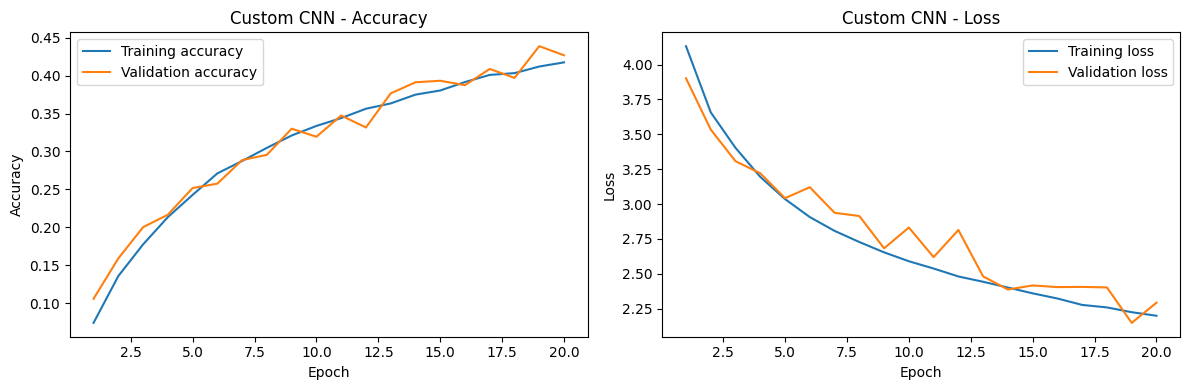

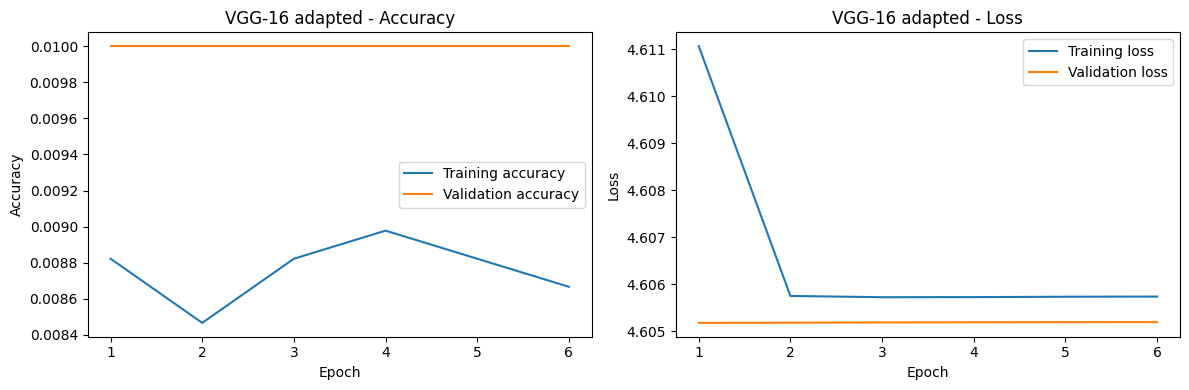

In [15]:
def plot_history(history, model_name):
    epochs = range(1, len(history.history["loss"]) + 1)
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history.history["accuracy"], label="Training accuracy")
    plt.plot(epochs, history.history["val_accuracy"], label="Validation accuracy")
    plt.title(f"{model_name} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history.history["loss"], label="Training loss")
    plt.plot(epochs, history.history["val_loss"], label="Validation loss")
    plt.title(f"{model_name} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history_custom, "Custom CNN")
plot_history(history_vgg16, "VGG-16 adapted")

## 8. Test evaluation and comparison

In [16]:
custom_loss, custom_acc = custom_cnn.evaluate(x_test, y_test, verbose=0)
vgg_loss, vgg_acc = vgg16_model.evaluate(x_test, y_test, verbose=0)

results = pd.DataFrame({
    "Model": ["Custom CNN", "VGG-16 (CIFAR-100 adapted)"],
    "Test Loss": [custom_loss, vgg_loss],
    "Test Accuracy (%)": [custom_acc * 100, vgg_acc * 100]
})
display(results.round(2))
print("Higher test accuracy:", results.loc[results["Test Accuracy (%)"].idxmax(), "Model"])

,Model,Test Loss,Test Accuracy (%)
0,Custom CNN,2.12,44.35
1,VGG-16 (CIFAR-100 adapted),4.61,1.00


Higher test accuracy: Custom CNN


In [17]:
results.to_csv("cifar100_model_comparison.csv", index=False)

custom_cnn.save("custom_cnn_final.keras")
vgg16_model.save("vgg16_final.keras")

print("Results and models saved successfully.")

Results and models saved successfully.


In [18]:
print(f"Custom CNN test accuracy: {custom_acc * 100:.2f}%")
print(f"VGG-16 adapted test accuracy: {vgg_acc * 100:.2f}%")

if custom_acc > vgg_acc:
    print("Model with higher test accuracy: Custom CNN")
elif vgg_acc > custom_acc:
    print("Model with higher test accuracy: VGG-16 adapted")
else:
    print("Both models have equal test accuracy")

Custom CNN test accuracy: 44.35%
VGG-16 adapted test accuracy: 1.00%
Model with higher test accuracy: Custom CNN
